# 소나무 병해충발생수 분석

#### '감염목'과 '미감염' 개수를 연도별로 집계하여 하나의 요약 데이터프레임(df_result)으로 만들었습니다.

In [1]:
import pandas as pd

file_list = [
    '병해충발생정보관리/병해충발생정보관리_2023.csv',
    '병해충발생정보관리/병해충발생정보관리_2022.csv',
    '병해충발생정보관리/병해충발생정보관리_2021.csv',
    '병해충발생정보관리/병해충발생정보관리_2020.csv',
    '병해충발생정보관리/병해충발생정보관리_2019.csv',
    '병해충발생정보관리/병해충발생정보관리_2018.csv',
    '병해충발생정보관리/병해충발생정보관리_2017.csv',
    '병해충발생정보관리/병해충발생정보관리_2016.csv'
]

results = []

for file_path in file_list:
    try:
        year = file_path[-8:-4]
        df = pd.read_csv(file_path, encoding='cp949', low_memory=False)
        has_count = (df == '감염목').sum().sum()
        none_count = (df == '미감염').sum().sum()
        
        results.append({
            '연도': year,      
            '감염목_개수': has_count,
            '미감염_개수': none_count
        })
    except Exception as e:
        print(f"파일 처리 중 오류 발생 ({file_path}): {e}")

df_result = pd.DataFrame(results)
df_result

,연도,감염목_개수,미감염_개수
0,2023,163522,262757
1,2022,377401,550308
2,2021,298569,616024
3,2020,304734,821005
4,2019,388949,1176126
5,2018,486431,1421269
6,2017,659146,1487130
7,2016,507514,753438


#### 연도별 감염목과 미감염목 개수의 추이를 파악할 수 있는 꺾은 선 그래프를 그린 코드입니다.

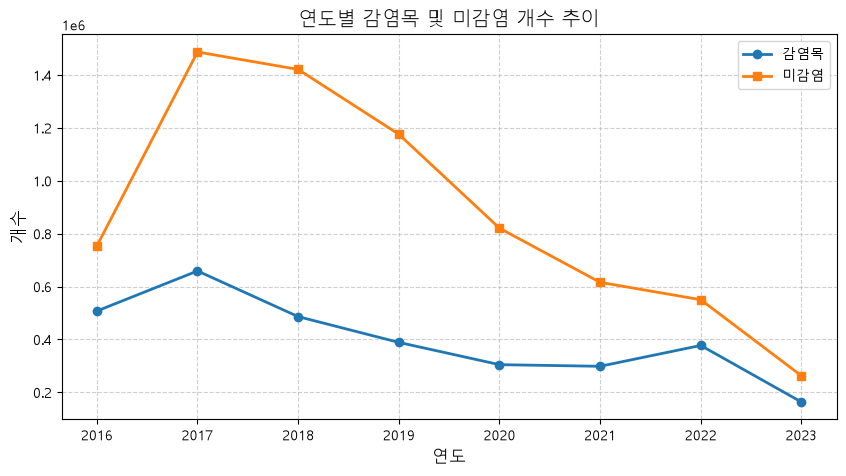

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False

df_result['연도'] = df_result['연도'].astype(int)
df_result = df_result.sort_values(by='연도', ascending=True).reset_index(drop=True)

plt.figure(figsize=(10, 5))

plt.plot(df_result['연도'], df_result['감염목_개수'], marker='o', linewidth=2, label='감염목')
plt.plot(df_result['연도'], df_result['미감염_개수'], marker='s', linewidth=2, label='미감염')

plt.title('연도별 감염목 및 미감염 개수 추이', fontsize=14)
plt.xlabel('연도', fontsize=12)
plt.ylabel('개수', fontsize=12)

plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

#### 전체 검사목중 감염목이 몇 퍼센트를 차지하는지를 감염목 개수와 비교하기 위한 코드입니다.

=== 연도별 감염 현황 및 감염률/증감률 분석 ===
     연도  감염목_개수     감염률(%)  감염목_증감률(%)
0  2016  507514  40.248479         NaN
1  2017  659146  30.711148   29.877402
2  2018  486431  25.498296  -26.202844
3  2019  388949  24.851780  -20.040252
4  2020  304734  27.069685  -21.651939
5  2021  298569  32.645013   -2.023076
6  2022  377401  40.680968   26.403277
7  2023  163522  38.360323  -56.671551 



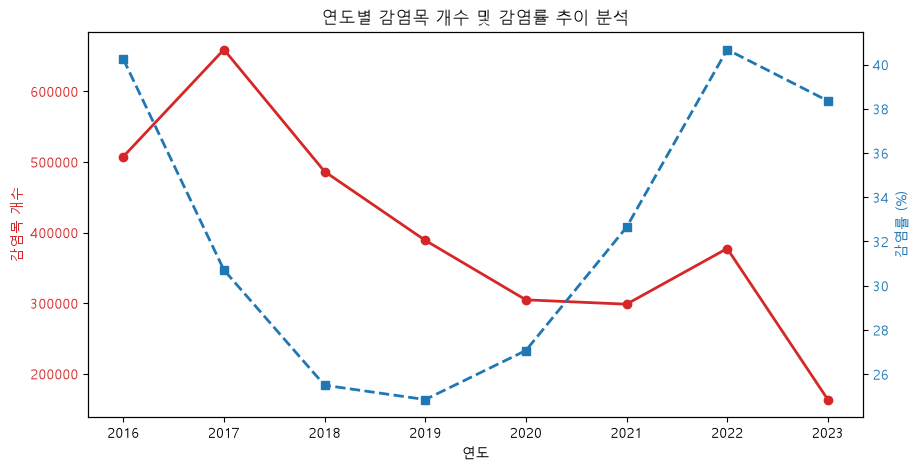

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

df_sorted = df_result.sort_values('연도').reset_index(drop=True)

df_sorted['총검사목수'] = (
    df_sorted['감염목_개수'] + df_sorted['미감염_개수']
)
df_sorted['감염률(%)'] = (
    df_sorted['감염목_개수'] / df_sorted['총검사목수']
) * 100

df_sorted['감염목_증감률(%)'] = (
    df_sorted['감염목_개수'].pct_change() * 100
)

print('=== 연도별 감염 현황 및 감염률/증감률 분석 ===')
print(df_sorted[['연도', '감염목_개수', '감염률(%)', '감염목_증감률(%)']], '\n')

fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:red'
ax1.set_xlabel('연도')
ax1.set_ylabel('감염목 개수', color=color)
ax1.plot(
    df_sorted['연도'],
    df_sorted['감염목_개수'],
    marker='o',
    color=color,
    linewidth=2,
    label='감염목 개수',
)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('감염률 (%)', color=color)
ax2.plot(
    df_sorted['연도'],
    df_sorted['감염률(%)'],
    marker='s',
    linestyle='--',
    color=color,
    linewidth=2,
    label='감염률(%)',
)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('연도별 감염목 개수 및 감염률 추이 분석')
plt.show()

# 지역별 소나무이동 반출금지구역 면적

#### 소나무류 반출금지구역의 면적을 지역별로 비교하여 분석하기 위해 데이터를 불러온 후 전처리를 진행하였습니다.

In [4]:
import pandas as pd
file_path = '산림청_산림병해충방제 소나무이동 반출금지구역관리정보_20260701.xlsx'
df = pd.read_excel(file_path)

df_filtered = (
    df[df.iloc[:, 0].apply(lambda x: isinstance(x, str))]
    .pipe(lambda x: x[x.iloc[:, 1].notna()])
    .drop(columns=df.columns[[4, 5, 7]])
    .set_index(df.columns[0])
)

df_filtered.columns = ['시군구수', '행정동수', '행정리수', '반출금지구역면적']
df_filtered = df_filtered.apply(pd.to_numeric, errors='coerce').fillna(0)
df_filtered = df_filtered.drop('시·도', errors='ignore') 

df_filtered

,시군구수,행정동수,행정리수,반출금지구역면적
전국 소나무류반출금지구역 지정현황,,,,
서울,8.0,34.0,0.0,9.368000e+03
부산,16.0,206.0,62.0,7.753000e+04
대구,7.0,49.0,155.0,1.137870e+05
광주,4.0,29.0,0.0,3.275000e+04
대전,5.0,19.0,0.0,2.839800e+04
울산,5.0,45.0,118.0,1.006810e+05
세종,1.0,0.0,62.0,2.570200e+04
경기,25.0,214.0,876.0,6.648347e+05
강원,11.0,24.0,636.0,4.004984e+05


#### 지역별 도시림 전체 면적 데이터를 활용하기 위한 파일을 불러왔습니다.

In [5]:
import glob
import pandas as pd

file_path = "산림청_도시림 면적현황 세부내역_20200918.csv"
df = pd.read_csv(file_path, encoding='cp949', low_memory=False)
col_0 = df.columns[0]
col_2 = df.columns[2]
df_subset = df[[col_0, col_2]].copy()
df_subset[col_2] = pd.to_numeric(df_subset[col_2], errors='coerce').fillna(0)

df_grouped = df_subset.groupby(col_0, as_index=False).sum()
df_grouped

,시도,합계(단위 : ㎡)
0,강원,2.852894e+09
1,경기,1.355926e+09
2,경남,7.094365e+08
3,경북,1.611798e+09
4,광주,1.823386e+08
5,대구,2.841336e+08
6,대전,2.474211e+08
7,부산,2.925429e+08
8,서울,1.470125e+08
9,세종,1.265931e+07


#### 위의 두 데이터를 지역별로 병합한 데이터프레임 생성하였습니다.

In [6]:
import pandas as pd

df_grouped.columns = ['시도', '도시림 면적']

df_filtered_reset = df_filtered.reset_index()
df_filtered_reset.rename(columns={df_filtered_reset.columns[0]: '시도'}, inplace=True)

df_merged = pd.merge(df_filtered_reset, df_grouped, on='시도', how='inner')
df_merged = df_merged.set_index('시도')
df_merged

,시군구수,행정동수,행정리수,반출금지구역면적,도시림 면적
시도,,,,,
서울,8.0,34.0,0.0,9.368000e+03,1.470125e+08
부산,16.0,206.0,62.0,7.753000e+04,2.925429e+08
대구,7.0,49.0,155.0,1.137870e+05,2.841336e+08
광주,4.0,29.0,0.0,3.275000e+04,1.823386e+08
대전,5.0,19.0,0.0,2.839800e+04,2.474211e+08
울산,5.0,45.0,118.0,1.006810e+05,3.254425e+08
세종,1.0,0.0,62.0,2.570200e+04,1.265931e+07
경기,25.0,214.0,876.0,6.648347e+05,1.355926e+09
강원,11.0,24.0,636.0,4.004984e+05,2.852894e+09


#### 지역별 반출금지구역면적을 한눈에 볼 수 있는 막대그래프를 그린 코드입니다.

=== [분석 1] 시·도별 반출금지구역 면적 순위 ===
    시도      반출금지구역면적
0   경북  1.489762e+06
1   경남  8.122171e+05
2   경기  6.648347e+05
3   전남  4.402771e+05
4   충남  4.290339e+05
5   강원  4.004984e+05
6   전북  2.254614e+05
7   제주  1.821840e+05
8   충북  1.488076e+05
9   대구  1.137870e+05
10  울산  1.006810e+05
11  부산  7.753000e+04
12  광주  3.275000e+04
13  대전  2.839800e+04
14  세종  2.570200e+04
15  서울  9.368000e+03 



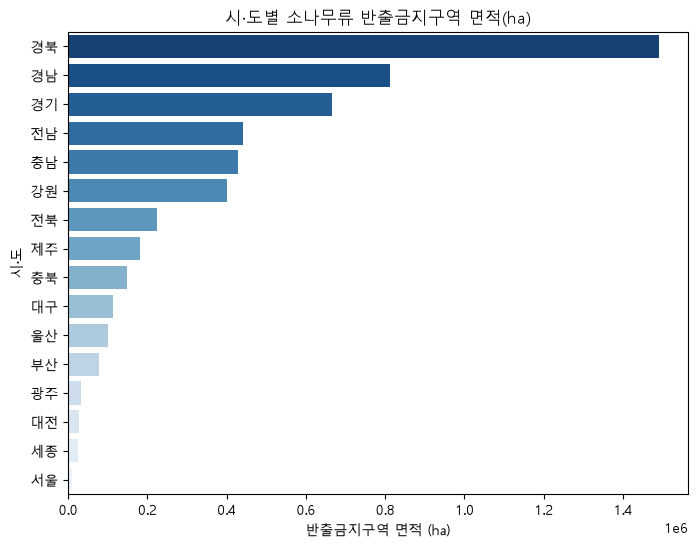

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

df_area = (
    df_filtered.groupby(df_filtered.index)['반출금지구역면적']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

df_area.columns = ['시도', '반출금지구역면적']

print('=== [분석 1] 시·도별 반출금지구역 면적 순위 ===')
print(df_area, '\n')

plt.figure(figsize=(8, 6)) 
sns.barplot(
    data=df_area,
    x='반출금지구역면적',  
    y='시도',  
    hue='시도',
    palette='Blues_r',
    legend=False,
)

plt.title('시·도별 소나무류 반출금지구역 면적(ha)')
plt.xlabel('반출금지구역 면적 (ha)')
plt.ylabel('시·도')
plt.yticks(rotation=0) 
plt.show()

#### 도시림 면적과 소나무류 반출금지구역의 면적을 회귀분석을 통해 파악하고 시각화한 코드입니다.

                            OLS Regression Results                            
Dep. Variable:               반출금지구역면적   R-squared:                       0.318
Model:                            OLS   Adj. R-squared:                  0.269
Method:                 Least Squares   F-statistic:                     6.531
Date:                Thu, 12 Nov 2026   Prob (F-statistic):             0.0229
Time:                        15:56:31   Log-Likelihood:                -225.24
No. Observations:                  16   AIC:                             454.5
Df Residuals:                      14   BIC:                             456.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       9.632e+04   1.22e+05      0.787      0.4

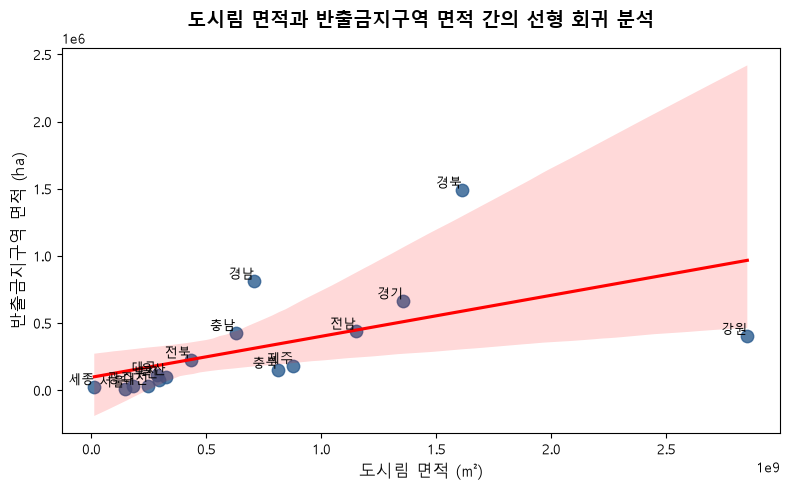

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False

X = df_merged['도시림 면적']
y = df_merged['반출금지구역면적']

X_sm = sm.add_constant(X)
model = sm.OLS(y, X_sm).fit()
print(model.summary())

plt.figure(figsize=(8, 5))

sns.regplot(
    data=df_merged,
    x='도시림 면적',
    y='반출금지구역면적',
    color='#2b5c8f',
    scatter_kws={'s': 80},
    line_kws={'color': 'red'}
)

for i in range(len(df_merged)):
    plt.text(
        df_merged['도시림 면적'].iloc[i], 
        df_merged['반출금지구역면적'].iloc[i], 
        df_merged.index[i], 
        fontsize=9, 
        ha='right', 
        va='bottom'
    )

plt.title('도시림 면적과 반출금지구역 면적 간의 선형 회귀 분석', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('도시림 면적 (㎡)', fontsize=12)
plt.ylabel('반출금지구역 면적 (ha)', fontsize=12)

plt.tight_layout()
plt.show()